# Consulta Prévia contracts

Contracts whose `tipo_procedimento` is a Consulta Prévia variant: `Consulta Prévia` (331 977), `Consulta Prévia Simplificada` (2 520) and the Lei 30/2021 art. 7.º variant (53).

**Rule:** `tipo_procedimento` lowercased and accent-folded `.str.starts_with("consulta previa")`. Reference: **334,550 rows** on the current parquet.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import load_contracts
from base_gov.entities import (
    canonical_names,
    entity_key,
    explode_entities,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()
print(contracts["adjudicante_key_source"].value_counts(sort=True))

rows=2,295,074  cols=30
disregarded 12,658 contracts with |preco_contratual| < €10 (0.55%); kept 2,282,416
valor_por_dia defined for 97.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)
shape: (2, 2)
┌────────────────────────┬─────────┐
│ adjudicante_key_source ┆ count   │
│ ---                    ┆ ---     │
│ str                    ┆ u32     │
╞════════════════════════╪═════════╡
│ nipc                   ┆ 2282390 │
│ name                   ┆ 26      │
└────────────────────────┴─────────┘


In [3]:
CPREV_EXPR = (
    pl.col("tipo_procedimento")
    .str.to_lowercase()
    .str.replace_all("ú", "u")
    .str.replace_all("é", "e")
    .str.starts_with("consulta previa")
)
contracts["tipo_procedimento"].value_counts(sort=True)

tipo_procedimento,count
str,u32
"""Ajuste Direto Regime Geral""",1316104
"""Consulta Prévia""",331977
"""Concurso público""",266980
"""Ao abrigo de acordo-quadro (ar…",225281
"""Ao abrigo de acordo-quadro (ar…",49652
"""Contratação excluída II""",40152
"""Ajuste direto simplificado""",37935
"""Concurso limitado por prévia q…",4381
"""Setores especiais – isenção pa…",3937


In [4]:
proc = contracts.filter(CPREV_EXPR)
print(f"Consulta Prévia rows: {proc.height:,}  share by count: {proc.height / contracts.height:.1%}  "
      f"share by value: {proc['preco_contratual'].sum() / contracts['preco_contratual'].sum():.1%}")
variants = proc["tipo_procedimento"].value_counts(sort=True)
display(variants)
assert variants["count"].sum() == proc.height and proc.height < contracts.height
variants

n_before = contracts_all.filter(CPREV_EXPR).height
n_after = proc.height
assert n_after <= n_before
print(f"{n_before:,} before the €{MIN_VALUE:g} flag, {n_after:,} after "
      f"({n_before - n_after:,} flagged below the threshold)")

Consulta Prévia rows: 334,550  share by count: 14.7%  share by value: 7.0%


tipo_procedimento,count
str,u32
"""Consulta Prévia""",331977
"""Consulta Prévia Simplificada""",2520
"""Consulta prévia ao abrigo do a…",53


335,283 before the €10 flag, 334,550 after (733 flagged below the threshold)


In [5]:
# Effect of disregarding contracts with |value| below €10 on Consulta Prévia.
before = contracts_all.filter(CPREV_EXPR)
display(value_impact(before, proc))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",335283.0,334550.0,-733.0,-0.22
"""mean_value""",33168.25254,33240.920174,72.667634,0.22
"""median_value""",19868.6,19900.0,31.4,0.16
"""total_value""",1.1121e10,1.1121e10,-1372.260004,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 625 of 334,550


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
16.0,40.0,152.0,365.0,730.0,11.83,35.6,122.22,542.61,1461.6


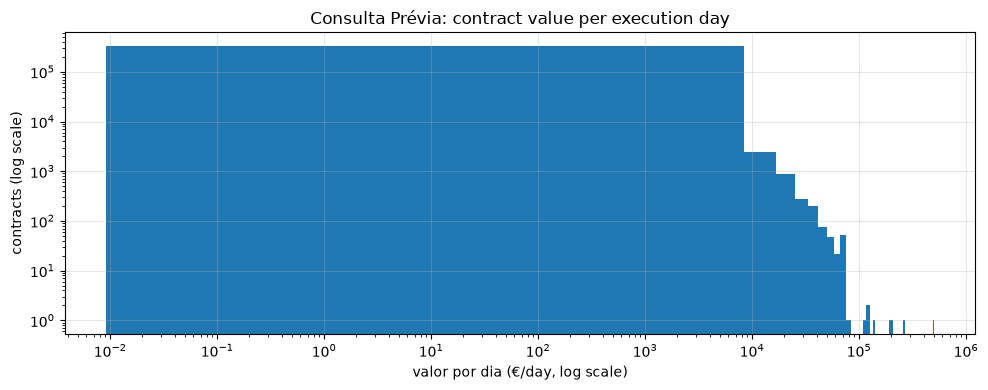

In [6]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = proc
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Consulta Prévia: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    proc.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",79357,13750.93,793.33,1.8140e9
"""91-365 d""",140716,15984.25,57.72,4.1694e9
"""31-90 d""",62536,29720.4,479.17,2.6040e9
"""366-3650 d""",51316,31200.0,39.45,2.3346e9


In [8]:
# One row per (contract, awardee), keyed by NIPC; name similarity only for the "-" (no NIF) sentinel.
awardees = entity_key(explode_entities(proc, "adjudicatarios", prefix="adjudicatarios"), prefix="adjudicatarios")
print(awardees["adjudicatarios_status"].value_counts(sort=True))
print(awardees["adjudicatarios_key_source"].value_counts(sort=True))

shape: (2, 2)
┌───────────────────────┬────────┐
│ adjudicatarios_status ┆ count  │
│ ---                   ┆ ---    │
│ str                   ┆ u32    │
╞═══════════════════════╪════════╡
│ YES                   ┆ 307320 │
│ NO_NIF                ┆ 28371  │
└───────────────────────┴────────┘
shape: (2, 2)
┌───────────────────────────┬────────┐
│ adjudicatarios_key_source ┆ count  │
│ ---                       ┆ ---    │
│ str                       ┆ u32    │
╞═══════════════════════════╪════════╡
│ nipc                      ┆ 307320 │
│ name                      ┆ 28371  │
└───────────────────────────┴────────┘


In [9]:
by_adjudicante = (
    proc.group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .join(canonical_names(proc, prefix="adjudicante"), on="adjudicante_key", how="left")
)
print("Top 20 adjudicantes by Consulta Prévia count:")
display(by_adjudicante.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicantes by Consulta Prévia value:")
display(by_adjudicante.sort("total_value", descending=True).head(20))

Top 20 adjudicantes by Consulta Prévia count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""600012662""",5486,4.1822e7,"""MARINHA - Direção de Abastecim…"
"""511228848""",4872,8.1055e7,"""Serviço de Saúde da Região Aut…"
"""508481287""",3607,4.2518e7,"""Unidade Local de Saúde de Sant…"
"""510103448""",2544,3.0462e7,"""Unidade Local de Saúde de Coim…"
"""501442600""",2272,3.8597e7,"""Instituto do Emprego e da Form…"
"""500051070""",2177,1.1935e8,"""Município de Lisboa"""
"""500051062""",1954,3.8970e7,"""Município de Sintra"""
"""500745943""",1885,1.0405e8,"""Município de Oeiras"""
"""501413197""",1708,4.8782e7,"""Universidade do Porto - Faculd…"



Top 20 adjudicantes by Consulta Prévia value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""503933813""",987,2.4192e8,"""Infraestruturas de Portugal, S…"
"""500051070""",2177,1.1935e8,"""Município de Lisboa"""
"""505187531""",1026,1.0683e8,"""Município de Cascais"""
"""500745943""",1885,1.0405e8,"""Município de Oeiras"""
"""506614913""",1395,9.0357e7,"""Município de Vila Franca de Xi…"
"""506173968""",1531,8.8454e7,"""Município do Seixal"""
"""500192855""",128,8.1346e7,"""Metropolitano de Lisboa, EPE"""
"""511228848""",4872,8.1055e7,"""Serviço de Saúde da Região Aut…"
"""504293125""",1186,7.8777e7,"""Município de Odivelas"""


In [10]:
# One row per (contract, awardee). Contract value is not split between awardees: for multi-awardee
# contracts the value is counted in full for each awardee (state this when reading the table).
awardees = awardees.join(proc.select("idcontrato", "preco_contratual"), on="idcontrato", how="left")
by_awardee = (
    awardees.group_by("adjudicatarios_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
        pl.col("adjudicatarios_key_source").first().alias("key_source"),
    )
    .join(canonical_names(awardees, prefix="adjudicatarios"), on="adjudicatarios_key", how="left")
)
print("Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):")
display(by_awardee.sort("n_contracts", descending=True).head(20))
print("\nTop 20 adjudicatarios by value:")
display(by_awardee.sort("total_value", descending=True).head(20))
n_name = awardees.filter(pl.col("adjudicatarios_key_source") == "name").height
print(f"awardee entries keyed by name fallback: {n_name:,} of {awardees.height:,} ({n_name / awardees.height:.1%})")

Top 20 adjudicatarios by count (key_source 'name' = similarity-clustered, no NIF):


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""508831989""",1870,1.7862e7,"""nipc""","""OLMAR - Artigos de Papelaria, …"
"""504615947""",1414,4.1271e7,"""nipc""","""MEO - Serviços de Comunicações…"
"""503183997""",975,1.0354e7,"""nipc""","""Lactogal-Produtos Alimentares,…"
"""501506543""",855,8.0931e6,"""nipc""","""B. BRAUN MEDICAL, UNIPESSOAL L…"
"""500675252""",828,6.2316e6,"""nipc""","""Lardomus"""
"""500853975""",784,3.7144e6,"""nipc""","""Manuel Rui Azinhais Nabeiro, L…"
"""503842770""",778,5.2923e6,"""nipc""","""VWR International - Material d…"
"""500271518""",670,9.7186e6,"""nipc""","""Sogenave - Sociedade Geral de …"
"""505042037""",640,5.2805e6,"""nipc""","""Sumol + Compal Marcas, S.A."""



Top 20 adjudicatarios by value:


adjudicatarios_key,n_contracts,total_value,key_source,adjudicatarios_name
str,u32,f64,str,str
"""NAME::alcatel submarine networ…",1,1.39e8,"""name""","""Alcatel Submarine Networks"""
"""507513908""",29,8.3528e7,"""nipc""","""I-Sete Inovação Soluções Econó…"
"""514153652""",14,8.0433e7,"""nipc""","""AMENER - EFICIÊNCIA ENERGÉTICA…"
"""517474115""",1,6.9933e7,"""nipc""","""ZAGOPE,COMSA, ACE e FERGRUPO –…"
"""NAME::hengtong optic-electric,…",1,4.7000e7,"""name""","""Hengtong Optic-Electric, CO. L…"
"""500126623""",188,4.4435e7,"""nipc""","""Gertal - Companhia Geral de Re…"
"""504615947""",1414,4.1271e7,"""nipc""","""MEO - Serviços de Comunicações…"
"""502124083""",45,3.7113e7,"""nipc""","""Iberdrola Clientes Portugal, U…"
"""503504564""",361,3.4267e7,"""nipc""","""EDP Comercial - Comercializaçã…"


awardee entries keyed by name fallback: 28,371 of 335,691 (8.5%)


In [11]:
# Effect of NIPC-first keying: entity rows the old (nipc, name) grouping produced vs the key grouping.
old = proc.group_by("adjudicante_key", "adjudicante_name").len()
new = proc.group_by("adjudicante_key").len()
print(f"adjudicante rows: {old.height:,} (key, name spelling) -> {new.height:,} keys")
old_a = awardees.group_by("adjudicatarios_key", "adjudicatarios_name").len()
print(f"adjudicatario rows: {old_a.height:,} (key, name) -> {awardees['adjudicatarios_key'].n_unique():,} keys")
biggest = (
    proc.group_by("adjudicante_key")
    .agg(pl.col("adjudicante_name").n_unique().alias("n_spellings"), pl.len().alias("n_contracts"))
    .sort("n_spellings", descending=True)
    .head(5)
)
display(biggest)

adjudicante rows: 7,023 (key, name spelling) -> 6,960 keys
adjudicatario rows: 118,177 (key, name) -> 55,061 keys


adjudicante_key,n_spellings,n_contracts
str,u32,u32
"""510103448""",3,2544
"""506818829""",2,199
"""680015124""",2,206
"""500792887""",2,239
"""508142156""",2,459


shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 334550.0      │
│ null_count ┆ 0.0           │
│ mean       ┆ 33240.920174  │
│ std        ┆ 301512.456761 │
│ min        ┆ -114400.0     │
│ 25%        ┆ 7220.0        │
│ 50%        ┆ 19900.0       │
│ 75%        ┆ 42980.49      │
│ max        ┆ 1.39e8        │
└────────────┴───────────────┘


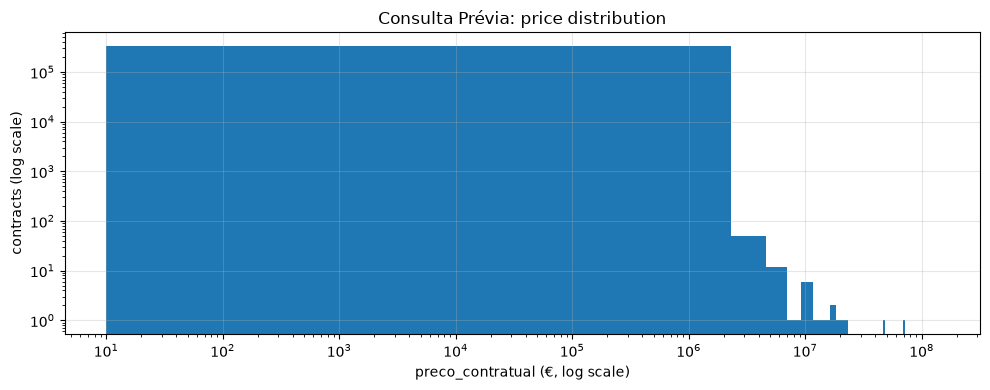

contracts above €5,000: 270,613
contracts above €20,000: 164,901
contracts above €75,000: 19,093


In [12]:
prices = proc["preco_contratual"].drop_nulls()
print(prices.describe())
fig, ax = plt.subplots()
ax.hist(prices.filter(prices > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("preco_contratual (€, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Consulta Prévia: price distribution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Informal reference points only, not legal advice.
for t in (5_000, 20_000, 75_000):
    print(f"contracts above €{t:,}: {(prices > t).sum():,}")

concorrentes reported: 74.7%
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 249832.0 │
│ null_count ┆ 0.0      │
│ mean       ┆ 2.431166 │
│ std        ┆ 3.045725 │
│ min        ┆ 1.0      │
│ 25%        ┆ 1.0      │
│ 50%        ┆ 2.0      │
│ 75%        ┆ 3.0      │
│ max        ┆ 103.0    │
└────────────┴──────────┘


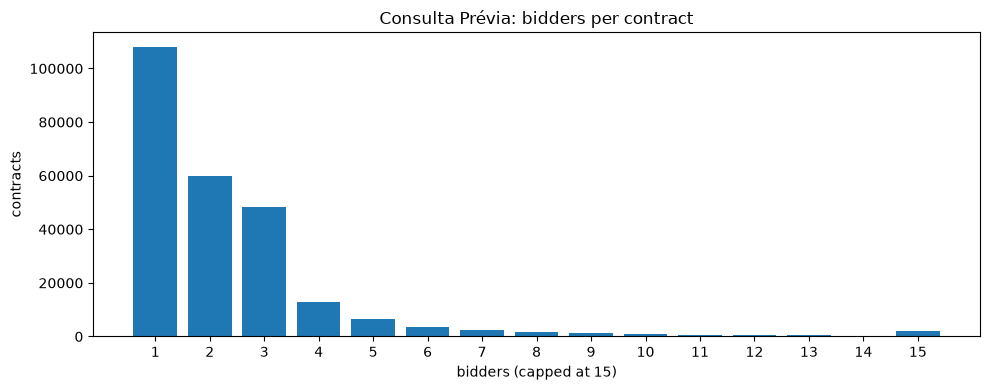

Single-bidder share among reported: 43.3%


tipo_procedimento,n_contracts,total_value,median_bidders
str,u32,f64,f64
"""Consulta Prévia""",331977,1.0709e10,2.0
"""Consulta Prévia Simplificada""",2520,4.06355943e8,2.0
"""Consulta prévia ao abrigo do a…",53,4.9474e6,2.0


In [13]:
# Competition: `concorrentes` is a "\n"-separated list of "NIPC-name" bidders (null = not reported).
proc = proc.with_columns(
    pl.col("concorrentes").str.split("\n").list.eval(pl.element().str.strip_chars().filter(pl.element() != "")).list.len().alias("n_concorrentes")
)
print(f"concorrentes reported: {proc['concorrentes'].is_not_null().mean():.1%}")
print(proc["n_concorrentes"].drop_nulls().describe())
fig, ax = plt.subplots()
counts = proc["n_concorrentes"].drop_nulls().clip(upper_bound=15).value_counts().sort("n_concorrentes")
ax.bar(counts["n_concorrentes"].cast(pl.String), counts["count"])
ax.set_xlabel("bidders (capped at 15)")
ax.set_ylabel("contracts")
ax.set_title("Consulta Prévia: bidders per contract")
plt.tight_layout()
plt.show()
print("Single-bidder share among reported:", f"{(proc['n_concorrentes'] == 1).sum() / proc['n_concorrentes'].drop_nulls().len():.1%}")

# Sub-split by variant: standard vs simplified vs Lei 30/2021
display(proc.group_by("tipo_procedimento").agg(
    pl.len().alias("n_contracts"),
    pl.col("preco_contratual").sum().round(2).alias("total_value"),
    pl.col("n_concorrentes").median().alias("median_bidders"),
).sort("n_contracts", descending=True))

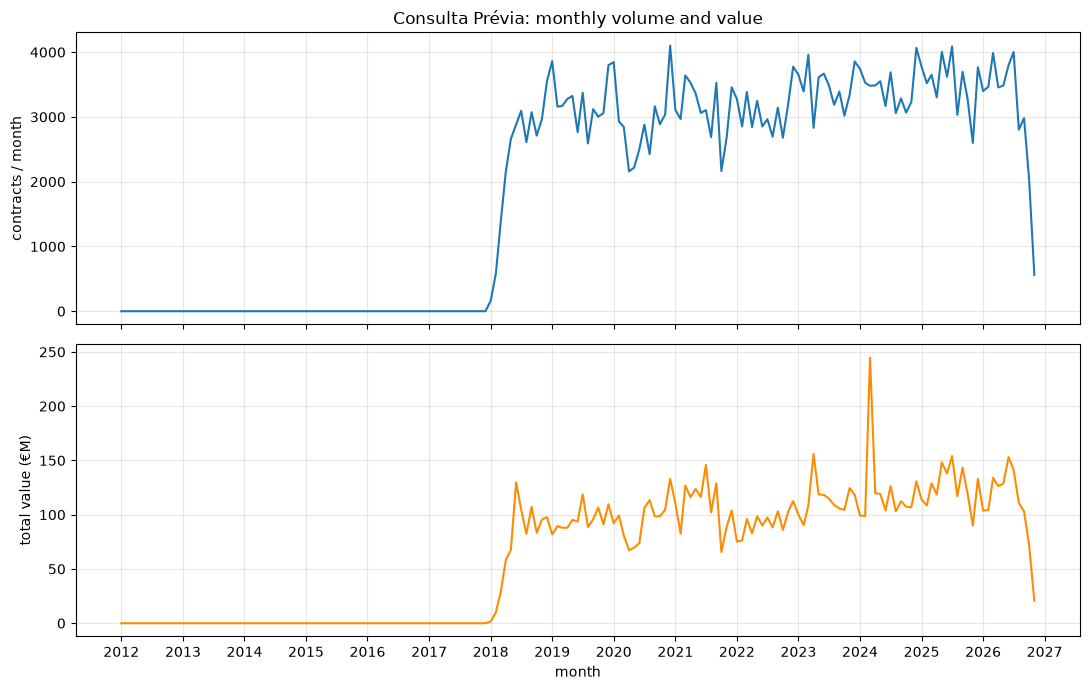

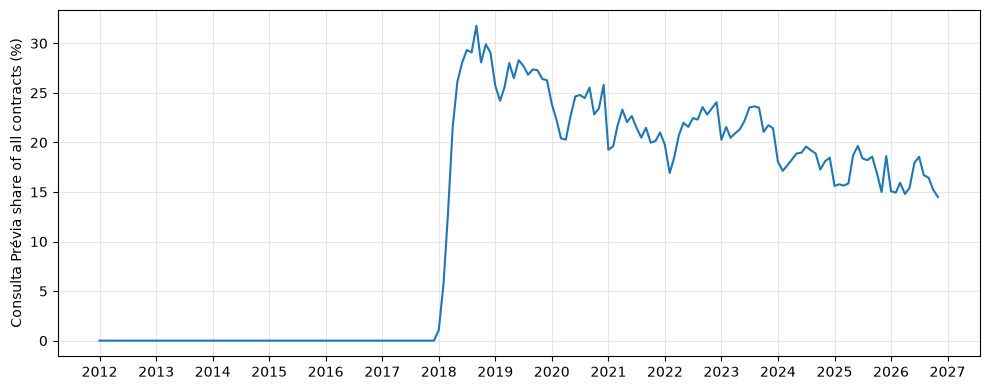

In [14]:
consulta_previa_monthly = (
    contracts.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(
        pl.len().alias("n_all"),
        CPREV_EXPR.sum().alias("n_contracts"),
        pl.col("preco_contratual").filter(CPREV_EXPR).sum().alias("total_value"),
    )
    .with_columns((pl.col("n_contracts") / pl.col("n_all")).alias("share"))
    .sort("month")
)
monthly = consulta_previa_monthly
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Consulta Prévia: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(consulta_previa_monthly["month"], consulta_previa_monthly["share"] * 100)
ax.set_ylabel("Consulta Prévia share of all contracts (%)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
proc.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)

idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
10617290,"""Infraestruturas de Portugal, S…",1.39e8,"""Consulta Prévia""",2024-03-13,"""FORNECIMENTO, INSTALAÇÃO, MONT…"
9978781,"""Metropolitano de Lisboa, EPE""",6.9933e7,"""Consulta Prévia""",2023-04-13,"""Empreitada de conceção e const…"
5898051,"""REN - Rede Eléctrica Nacional,…",4.7000e7,"""Consulta Prévia""",2018-06-25,"""EPC&M para a Ligação Centrais …"
7451620,"""Município de Vila Nova de Gaia""",2.1388e7,"""Consulta Prévia""",2021-01-19,"""CONTRATO DE GESTÃO DE EFICIÊNC…"
6476249,"""Portos dos Açores, SA""",1.8626874e7,"""Consulta Prévia""",2020-02-24,"""Empreitada de Protecção de Eme…"
6870485,"""Município de Odivelas""",1.7105e7,"""Consulta Prévia""",2020-08-24,"""Fornecimento de Refeições nos …"
7570291,"""Município de Cascais""",1.6992e7,"""Consulta Prévia""",2021-03-15,"""Aquisição de serviços de forne…"
10757887,"""Ren Atlântico - Terminal de Gn…",1.4025e7,"""Consulta Prévia""",2024-04-01,"""PC-2023-000640 - Fornecimento…"
8162860,"""MUNICÍPIO DE PALMELA""",1.2923e7,"""Consulta Prévia""",2021-07-06,"""Implementação de medidas de me…"


## Commentary and limitations

- `Ano` covers 2012–2026 (data up to 2026-11-14); edge months of the monthly series are partial.
- Awardee value totals count a multi-awardee contract in full for each awardee.
- Entities are keyed by NIPC. Entries with the `-` (no NIF) sentinel are clustered by name similarity
  (`token_sort_ratio >= 92`) and may over- or under-merge; see `key_source`. Dirty NIPCs stay separate keys.
- Very large values may be outliers or data-entry errors.
- Consulta Prévia invites a limited set of firms, so `concorrentes` reflects invited/bidding firms as reported.
- Contracts with |value| below €10 (`MIN_VALUE`, applied to the absolute value) are disregarded; the before/after cell quantifies the effect.
- `valor_por_dia` = `preco_contratual / prazo_execucao`, only for 1–3650 days (0-day and >10-year values are treated as data errors). Short contracts inflate €/day.